# Fundación YPF - Data Science
# Pre-entrega 3 - Grupo 7: Modelo de Aprendizaje Supervisado

**Consigna:** entrega del modelo de Aprendizaje Supervisado ajustado (regresión o clasificación), métricas de evaluación y optimización de hiperparámetros con Optuna.

## Índice

**Parte 0.** El problema y el dataset

**Parte 1.** La tarea: qué queremos predecir

**Parte 2.** La experiencia: variables, fuga de información y separación train/test

**Parte 3.** Preprocesamiento con `ColumnTransformer` y `Pipeline`

**Parte 4.** Modelos iniciales: piso de referencia, Regresión Lineal y Random Forest

**Parte 5.** Optimización de hiperparámetros con Optuna

**Parte 6.** Evaluación final sobre test y métricas

**Parte 7.** Interpretación: qué variables pesan más

**Parte 8.** Uso del modelo: predicción para un pozo nuevo

**Parte 9.** Conclusiones

## Dataset

`pozos_fractura_limpio.csv`: el dataset de fracturas de pozos de hidrocarburos (datos.gob.ar) que limpiamos en las pre-entregas anteriores.

## Parte 0. El problema

En los pozos petrolíferos se necesita una gran cantidad de arena para realizar las fracturas. Esta arena se suele llevar desde el interior de Argentina (Entre Ríos) o incluso se debe importar hasta donde se realiza la extracción, lo que suele ser más de 1000 km. Por lo que es útil poder predecir la cantidad necesaria de este insumo para cada proyecto y evitar excesos o faltantes, y así no incurrir en sobrecostos logísticos.

Por esta razón decidimos armar un **modelo de regresión para predecir la cantidad de arena total necesaria para futuras fracturas**.

In [ ]:
!pip install -q optuna

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Para que Optuna no imprima una línea por cada prueba
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [ ]:
def cargar(nombre):
    """Busca el archivo en /content/ (Colab) y, si no está, en el directorio local."""
    try:
        return pd.read_csv('/content/' + nombre)
    except FileNotFoundError:
        return pd.read_csv(nombre)

df = cargar('pozos_fractura_limpio.csv')
print(df.shape)
df.head()

(4888, 38)


,_id,id_base_fractura_adjiv,idpozo,sigla,cuenca,areapermisoconcesion,yacimiento,formacion_productiva,tipo_reservorio,subtipo_reservorio,longitud_rama_horizontal_m,cantidad_fracturas,tipo_terminacion,arena_bombeada_nacional_tn,arena_bombeada_importada_tn,agua_inyectada_m3,co2_inyectado_m3,presion_maxima_psi,potencia_equipos_fractura_hp,fecha_inicio_fractura,fecha_fin_fractura,fecha_data,anio_if,mes_if,anio_ff,mes_ff,anio_carga,mes_carga,empresa_informante,mes,anio,arena_total_tn,potencia_imputada,duracion_fractura_dias,es_horizontal,lecho_fluido_m3,Espaciamiento_entre_etapas,realcion_arena_fluido
0,1,30,159910,APS.Nq.ADC.xp-1033,neuquina,agua del cajon,agua del cajon,los molles,no convencional,shale,0.0,3,punzado,0.000,0.000,2718.20,0.0,10190.0,10897.0,2019-04-20,2019-04-30,2019-06-14 17:13:03,2019,4,2019,4,2019,6,capex s.a.,4,2019,0.000,False,10,False,2718.20,0.000000,0.000000
1,2,31,159910,APS.Nq.ADC.xp-1033,neuquina,agua del cajon,agua del cajon,los molles,no convencional,shale,0.0,1,punzado,0.000,0.000,600.00,0.0,9250.0,10251.0,2018-11-02,2018-11-03,2019-06-14 17:14:19,2018,11,2018,11,2019,6,capex s.a.,11,2018,0.000,False,1,False,600.00,0.000000,0.000000
2,3,37,159219,YPF.Nq.AdlA-1001(h),neuquina,aguada de la arena,aguada de la arena,vaca muerta,no convencional,shale,1437.3,18,tapón disparo,3761.370,536.850,25768.30,0.0,15000.0,32000.0,2017-11-19,2017-12-14,2019-06-27 13:46:21,2017,11,2017,12,2019,6,ypf s.a.,11,2017,4298.220,False,25,True,25768.30,79.850000,0.166803
3,4,38,159220,YPF.Nq.AdlA-1002(h),neuquina,aguada de la arena,aguada de la arena,vaca muerta,no convencional,shale,1518.3,19,tapón disparo,3903.705,558.225,27398.37,0.0,11348.0,32000.0,2017-11-21,2017-12-15,2019-06-27 13:46:21,2017,11,2017,12,2019,6,ypf s.a.,11,2017,4461.930,False,24,True,27398.37,79.910526,0.162854
4,5,39,159221,YPF.Nq.AdlA-1003(h),neuquina,aguada de la arena,aguada de la arena,vaca muerta,no convencional,shale,1482.3,19,tapón disparo,3949.020,569.925,27157.60,0.0,11076.0,32000.0,2017-11-18,2017-12-15,2019-06-27 13:46:21,2017,11,2017,12,2019,6,ypf s.a.,11,2017,4518.945,False,27,True,27157.60,78.015789,0.166397


## Parte 1. La tarea

Definir la tarea es responder tres preguntas:

1. **¿Qué queremos predecir?** La arena total bombeada en la fractura de un pozo (`arena_total_tn`), en toneladas.
2. **¿Es una categoría o un número?** Es un número continuo, así que es un problema de **regresión**.
3. **¿Para qué sirve?** Para planificar la logística de la arena antes de fracturar: cuántos camiones, cuánta arena importar y cuánta comprar a proveedores nacionales.

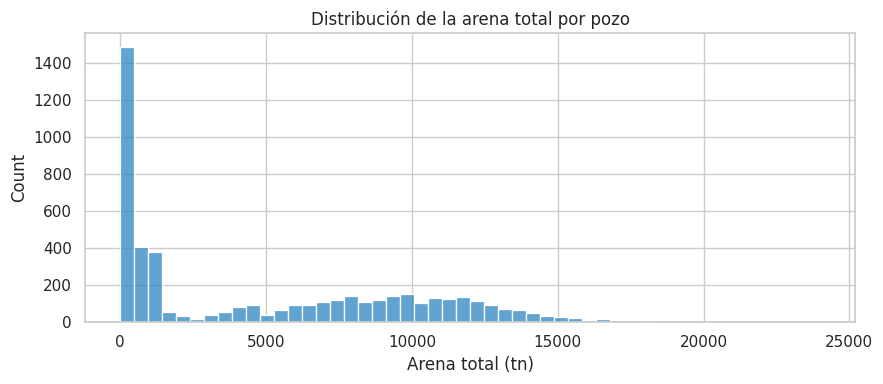

,arena_total_tn
count,4888.000000
mean,5044.356724
std,5076.494287
min,0.000000
25%,180.500000
50%,3538.662425
75%,9537.070000
max,24000.090000


In [ ]:
target = 'arena_total_tn'

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df[target], bins=50, color='#2E86C1', ax=ax)
ax.set_title('Distribución de la arena total por pozo')
ax.set_xlabel('Arena total (tn)')
plt.tight_layout()
plt.show()

df[target].describe()

La distribución tiene dos grupos: muchos pozos chicos (convencionales, con poca arena) y otro grupo grande de pozos no convencionales de Vaca Muerta que llevan miles de toneladas. Esto ya anticipa que el **tipo de reservorio** y la **formación** van a ser variables útiles.

## Parte 2. La experiencia

La experiencia son los datos de los que aprende el modelo. Los separamos en:

- `X`: las variables de entrada, lo que el modelo puede mirar.
- `y`: la variable objetivo, la respuesta que queremos que aprenda a dar.

### Fuga de información (*data leakage*)

Hay columnas que **no pueden quedar en `X`** porque se calcularon a partir de la arena o la contienen directamente. Si las dejamos, el modelo tendría la respuesta servida:

- `arena_bombeada_nacional_tn` y `arena_bombeada_importada_tn`: su suma **es** la arena total.
- `realcion_arena_fluido`: se calcula dividiendo la arena por el fluido.

Y dejamos afuera `lecho_fluido_m3` por otro motivo: es el agua más el CO₂ inyectado, así que repetiría casi la misma información que `agua_inyectada_m3`.

Tampoco usamos identificadores (`idpozo`, `sigla`, `_id`) ni fechas de carga, que no aportan información física sobre la fractura.

Nos quedamos con las variables que **se conocen al diseñar la fractura**, antes de bombear la arena.

In [ ]:
features_num = [
    'longitud_rama_horizontal_m',
    'cantidad_fracturas',
    'agua_inyectada_m3',
    'presion_maxima_psi',
    'potencia_equipos_fractura_hp',
    'duracion_fractura_dias',
]

features_cat = [
    'formacion_productiva',
    'tipo_reservorio',
]

X = df[features_num + features_cat]
y = df[target]

print('Dimensiones de X:', X.shape)
print('Dimensiones de y:', y.shape)
print()
print('Faltantes por columna:')
print(X.isna().sum())

Dimensiones de X: (4888, 8)
Dimensiones de y: (4888,)

Faltantes por columna:
longitud_rama_horizontal_m        0
cantidad_fracturas                0
agua_inyectada_m3               303
presion_maxima_psi                0
potencia_equipos_fractura_hp      0
duracion_fractura_dias            0
formacion_productiva              0
tipo_reservorio                   0
dtype: int64


`agua_inyectada_m3` tiene algunos faltantes. No los borramos a mano: los vamos a imputar **dentro del pipeline**, para que la mediana se calcule sólo con los datos de entrenamiento.

### Separar entrenamiento y test

Un modelo que responde bien sobre los mismos datos con los que aprendió no demuestra nada: puede haberlos memorizado. Por eso separamos un 20% de los pozos **antes de entrenar** y no los tocamos hasta la evaluación final.

Importante para Optuna: la búsqueda de hiperparámetros se hace **sólo con el conjunto de entrenamiento** (con validación cruzada). Si usáramos test para elegir los hiperparámetros, el test dejaría de ser "datos que el modelo nunca vio".

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f'Pozos de entrenamiento: {X_train.shape[0]}')
print(f'Pozos de test:          {X_test.shape[0]}')

Pozos de entrenamiento: 3910
Pozos de test:          978


## Parte 3. Preprocesamiento

Armamos el preprocesamiento con `ColumnTransformer`, igual que en la clase de Pipelines:

- **Numéricas:** imputación por la mediana y estandarización.
- **Categóricas:** imputación por la más frecuente y One-Hot Encoding. Con `min_frequency=20`, las formaciones con muy pocos pozos se agrupan en una sola categoría "rara", para no crear columnas casi vacías.

Al meter todo dentro de un `Pipeline`, el preprocesamiento se ajusta sólo con los datos de entrenamiento de cada pliegue y no hay fuga de información.

In [ ]:
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist',
                              min_frequency=20, sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, features_num),
    ('cat', cat_transformer, features_cat),
])

### Función auxiliar para las métricas

Usamos las tres métricas de regresión vistas en clase:

- **MAE** (error absoluto medio): en promedio, por cuántas toneladas se equivoca el modelo. Es la más fácil de leer.
- **RMSE** (raíz del error cuadrático medio): parecida al MAE pero castiga más los errores grandes. Está en toneladas.
- **R²**: qué proporción de la variación de la arena explica el modelo. 1 es perfecto, 0 es igual a predecir siempre el promedio.

In [ ]:
def metricas(y_real, y_pred):
    return {
        'MAE (tn)': mean_absolute_error(y_real, y_pred),
        'RMSE (tn)': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R2': r2_score(y_real, y_pred),
    }

## Parte 4. Modelos iniciales

Antes de optimizar nada, entrenamos tres modelos con sus valores por defecto:

1. **`DummyRegressor`**: el piso. Predice siempre el promedio de arena. Cualquier modelo útil tiene que superarlo.
2. **Regresión Lineal**: el modelo que veníamos usando en el grupo.
3. **Random Forest**: un conjunto de muchos árboles de decisión. Puede capturar relaciones no lineales (por ejemplo, que la arena no crece igual con las fracturas en un pozo convencional que en uno de Vaca Muerta).

Para compararlos de forma justa usamos **validación cruzada de 5 pliegues sobre el entrenamiento**: se entrena 5 veces, cada vez dejando afuera un quinto distinto para medir.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

modelos_base = {
    'Dummy (promedio)': DummyRegressor(strategy='mean'),
    'Regresión Lineal': LinearRegression(),
    'Random Forest (por defecto)': RandomForestRegressor(random_state=42, n_jobs=-1),
}

filas = []
for nombre, modelo in modelos_base.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', modelo)])
    rmse_cv = -cross_val_score(pipe, X_train, y_train, cv=kf,
                               scoring='neg_root_mean_squared_error')
    r2_cv = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2')
    filas.append({
        'Modelo': nombre,
        'RMSE CV (tn)': rmse_cv.mean(),
        'Desvío RMSE': rmse_cv.std(),
        'R2 CV': r2_cv.mean(),
    })

comparacion_base = pd.DataFrame(filas).round(3)
comparacion_base

,Modelo,RMSE CV (tn),Desvío RMSE,R2 CV
0,Dummy (promedio),5067.483,75.811,-0.000
1,Regresión Lineal,829.919,31.127,0.973
2,Random Forest (por defecto),654.164,27.083,0.983


Los dos modelos superan claramente al piso, así que sí aprenden algo. El Random Forest, aun sin ajustar, ya se equivoca menos que la regresión lineal. Por eso elegimos **Random Forest** como modelo a optimizar con Optuna.

## Parte 5. Optimización de hiperparámetros con Optuna

Los **hiperparámetros** son las perillas del modelo que no se aprenden de los datos, las elegimos nosotros antes de entrenar. En un Random Forest, por ejemplo:

| Hiperparámetro | Qué controla |
|---|---|
| `n_estimators` | Cuántos árboles tiene el bosque |
| `max_depth` | Qué tan profundo puede crecer cada árbol (más profundo = más complejo) |
| `min_samples_split` | Cuántos pozos tiene que haber en un nodo para poder partirlo |
| `min_samples_leaf` | Cuántos pozos como mínimo tiene que tener cada hoja |
| `max_features` | Qué fracción de variables mira cada árbol en cada corte |

Probar todas las combinaciones a mano sería eterno. **Optuna** lo hace por nosotros de forma inteligente: prueba una combinación, mide el error y usa ese resultado para elegir mejor la siguiente combinación.

Los tres pasos de Optuna:

1. **Función objetivo:** recibe un `trial` (una prueba), le pide a Optuna valores para cada hiperparámetro, entrena el modelo y devuelve el error.
2. **Estudio:** `optuna.create_study(direction='minimize')`, porque queremos el error más bajo.
3. **Optimizar:** `study.optimize(objetivo, n_trials=...)`.

El error que devolvemos es el **RMSE promedio de la validación cruzada sobre el entrenamiento**. El test no se toca.

In [ ]:
def objetivo(trial):
    # 1. Optuna propone valores para cada hiperparámetro
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
        'max_depth': trial.suggest_int('max_depth', 4, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_float('max_features', 0.3, 1.0),
    }

    # 2. Armamos el pipeline con esos valores
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(**params, random_state=42, n_jobs=-1)),
    ])

    # 3. Medimos el RMSE con validación cruzada (sólo sobre entrenamiento)
    rmse = -cross_val_score(pipe, X_train, y_train, cv=kf,
                            scoring='neg_root_mean_squared_error').mean()
    return rmse

In [ ]:
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),  # semilla para que sea reproducible
    study_name='rf_arena_total',
)

# 40 pruebas tardan unos minutos en Colab. Más pruebas = búsqueda más fina.
study.optimize(objetivo, n_trials=40)

print(f'Mejor RMSE en validación cruzada: {study.best_value:,.2f} tn')
print('Mejores hiperparámetros:')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')

Mejor RMSE en validación cruzada: 627.50 tn
Mejores hiperparámetros:
  n_estimators: 150
  max_depth: 12
  min_samples_split: 7
  min_samples_leaf: 1
  max_features: 0.4248629324157483


### ¿Cómo fue la búsqueda?

El primer gráfico muestra el error de cada prueba (puntos) y el mejor error encontrado hasta ese momento (línea). Si la línea se aplana, Optuna ya encontró una zona buena y seguir probando aporta poco.

El segundo muestra qué hiperparámetros influyeron más en el error.

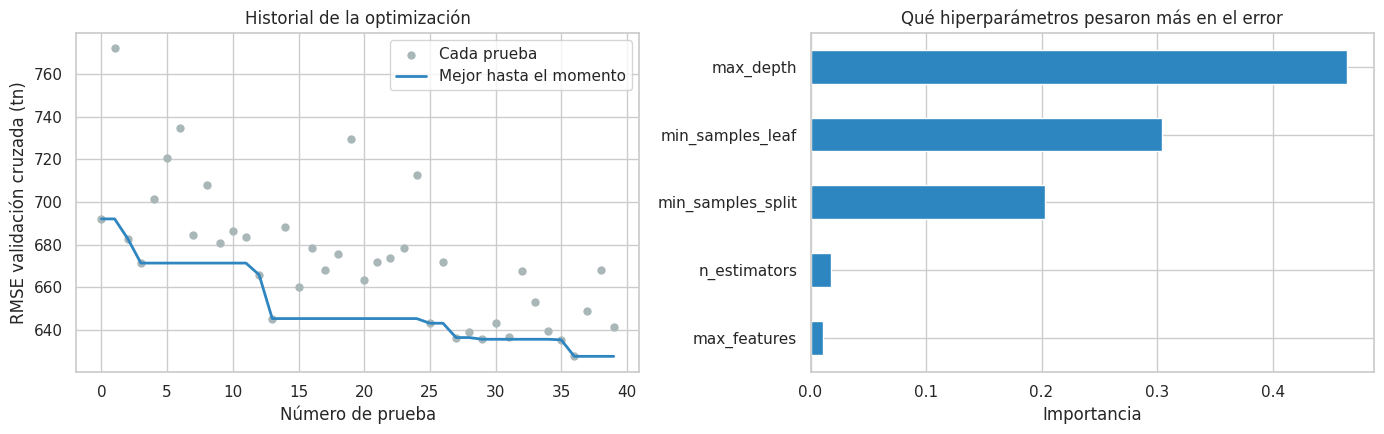

In [ ]:
historial = study.trials_dataframe()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(historial['number'], historial['value'], color='#AAB7B8', s=25, label='Cada prueba')
axes[0].plot(historial['number'], historial['value'].cummin(), color='#2E86C1', lw=2,
             label='Mejor hasta el momento')
axes[0].set_xlabel('Número de prueba')
axes[0].set_ylabel('RMSE validación cruzada (tn)')
axes[0].set_title('Historial de la optimización')
axes[0].legend()

importancia_hp = optuna.importance.get_param_importances(study)
pd.Series(importancia_hp).sort_values().plot.barh(ax=axes[1], color='#2E86C1')
axes[1].set_xlabel('Importancia')
axes[1].set_title('Qué hiperparámetros pesaron más en el error')

plt.tight_layout()
plt.show()

## Parte 6. Evaluación final sobre test

Ahora sí: entrenamos el Random Forest con los mejores hiperparámetros sobre **todo el entrenamiento** y lo medimos **una única vez** sobre el test, que el modelo nunca vio. Lo comparamos contra el piso, la regresión lineal y el Random Forest sin optimizar.

In [ ]:
def entrenar(modelo):
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', modelo)])
    pipe.fit(X_train, y_train)
    return pipe

modelos_finales = {
    'Dummy (promedio)': entrenar(DummyRegressor(strategy='mean')),
    'Regresión Lineal': entrenar(LinearRegression()),
    'Random Forest (por defecto)': entrenar(RandomForestRegressor(random_state=42, n_jobs=-1)),
    'Random Forest + Optuna': entrenar(RandomForestRegressor(**study.best_params,
                                                             random_state=42, n_jobs=-1)),
}

resultados_test = pd.DataFrame(
    {nombre: metricas(y_test, m.predict(X_test)) for nombre, m in modelos_finales.items()}
).T.round(3)

resultados_test

,MAE (tn),RMSE (tn),R2
Dummy (promedio),4579.492,5108.514,-0.000
Regresión Lineal,499.100,818.370,0.974
Random Forest (por defecto),294.377,625.974,0.985
Random Forest + Optuna,304.147,572.302,0.987


**Lectura de la tabla:**

- Todos los modelos superan con amplitud al piso, que se equivoca en promedio más de 4.500 tn.
- El Random Forest reduce el error de la regresión lineal: el MAE baja de unas 500 tn a unas 300 tn.
- La optimización con Optuna bajó el **RMSE**, que es la métrica que le pedimos minimizar, y subió el R². El **MAE** quedó prácticamente igual que el del Random Forest por defecto. Esto pasa porque el RMSE castiga más los errores grandes: Optuna encontró un modelo que se equivoca menos en los pozos "difíciles", aunque el error típico se mantiene. Para planificar arena nos conviene, porque un error grande es el que genera un faltante en boca de pozo.

In [ ]:
modelo_final = modelos_finales['Random Forest + Optuna']
y_pred = modelo_final.predict(X_test)

m_final = resultados_test.loc['Random Forest + Optuna']
m_lr = resultados_test.loc['Regresión Lineal']

print('=== MODELO FINAL: RANDOM FOREST OPTIMIZADO CON OPTUNA ===')
print(f"MAE : {m_final['MAE (tn)']:,.1f} tn")
print(f"RMSE: {m_final['RMSE (tn)']:,.1f} tn")
print(f"R²  : {m_final['R2']:.3f}")
print()
print(f"Mejora del MAE respecto de la Regresión Lineal: "
      f"{(1 - m_final['MAE (tn)'] / m_lr['MAE (tn)']):.1%}")
print(f"Error relativo medio respecto de la arena promedio en test: "
      f"{m_final['MAE (tn)'] / y_test.mean():.1%}")

=== MODELO FINAL: RANDOM FOREST OPTIMIZADO CON OPTUNA ===
MAE : 304.1 tn
RMSE: 572.3 tn
R²  : 0.987

Mejora del MAE respecto de la Regresión Lineal: 39.1%
Error relativo medio respecto de la arena promedio en test: 6.0%


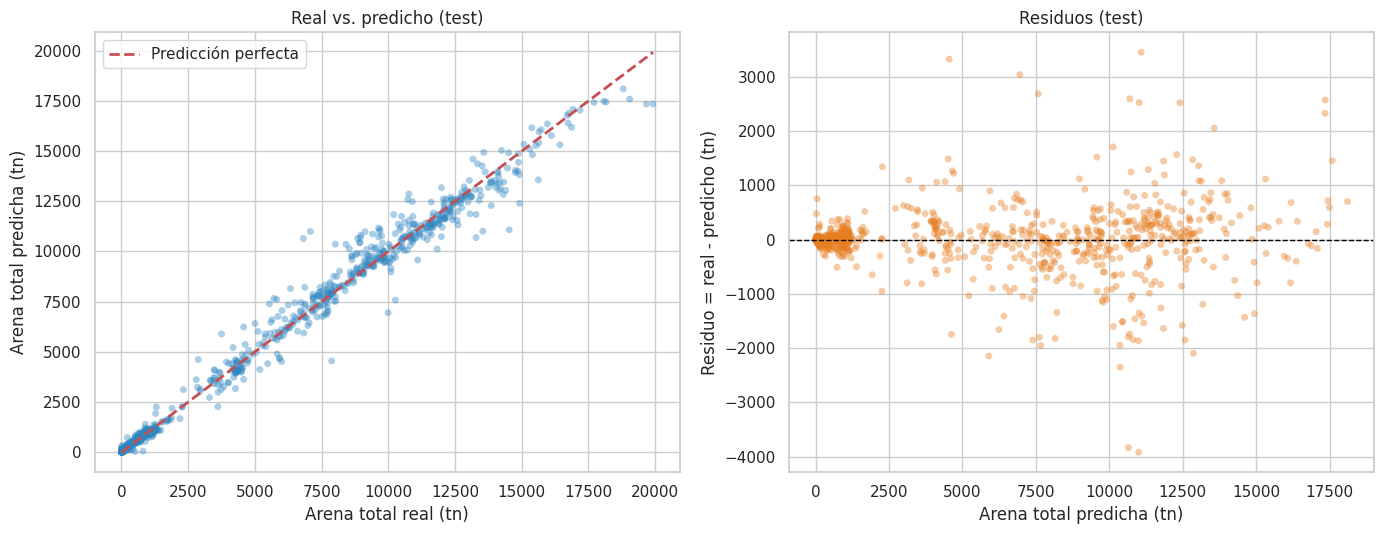

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Real vs. predicho
axes[0].scatter(y_test, y_pred, alpha=0.4, color='#2E86C1', edgecolors='none', s=25)
lim = max(y_test.max(), y_pred.max())
axes[0].plot([0, lim], [0, lim], 'r--', lw=2, label='Predicción perfecta')
axes[0].set_xlabel('Arena total real (tn)')
axes[0].set_ylabel('Arena total predicha (tn)')
axes[0].set_title('Real vs. predicho (test)')
axes[0].legend()

# Residuos
residuos = y_test - y_pred
axes[1].scatter(y_pred, residuos, alpha=0.4, color='#E67E22', edgecolors='none', s=25)
axes[1].axhline(0, color='black', ls='--', lw=1)
axes[1].set_xlabel('Arena total predicha (tn)')
axes[1].set_ylabel('Residuo = real - predicho (tn)')
axes[1].set_title('Residuos (test)')

plt.tight_layout()
plt.show()


- En el de la izquierda, cuanto más pegados están los puntos a la línea roja, mejor predice el modelo.
- En el de la derecha, los residuos deberían estar repartidos alrededor de cero sin un patrón claro. Se ve que el error crece con el tamaño del pozo: es esperable, porque equivocarse un 10% en un pozo de 15.000 tn son muchas más toneladas que en uno de 500 tn.

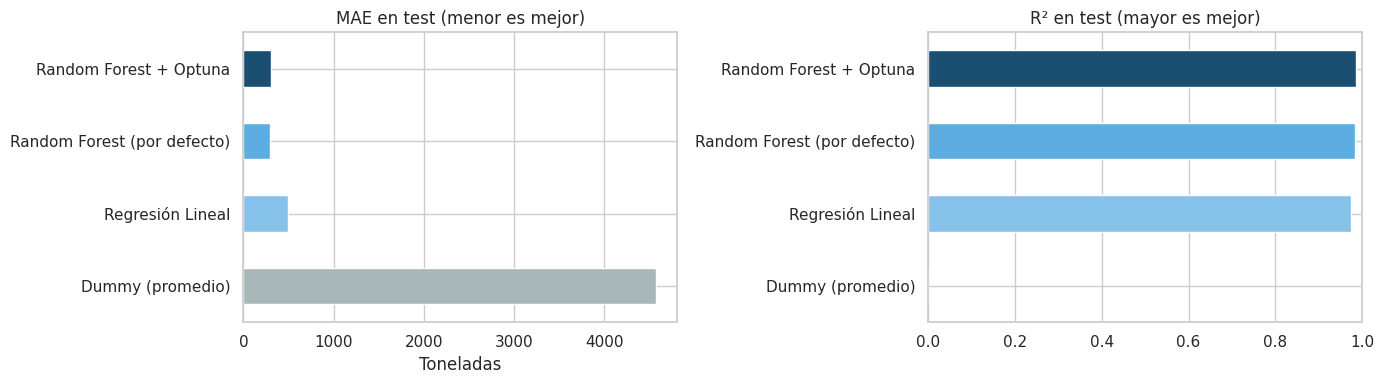

In [ ]:
# Comparación visual de las métricas en test
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
orden = resultados_test.index

resultados_test['MAE (tn)'].plot.barh(ax=axes[0], color=['#AAB7B8', '#85C1E9', '#5DADE2', '#1B4F72'])
axes[0].set_title('MAE en test (menor es mejor)')
axes[0].set_xlabel('Toneladas')

resultados_test['R2'].plot.barh(ax=axes[1], color=['#AAB7B8', '#85C1E9', '#5DADE2', '#1B4F72'])
axes[1].set_title('R² en test (mayor es mejor)')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

## Parte 7. Interpretación: qué variables pesan más

El Random Forest calcula cuánto usó cada variable para decidir. Recuperamos los nombres de las columnas después del One-Hot Encoding para poder leerlo.

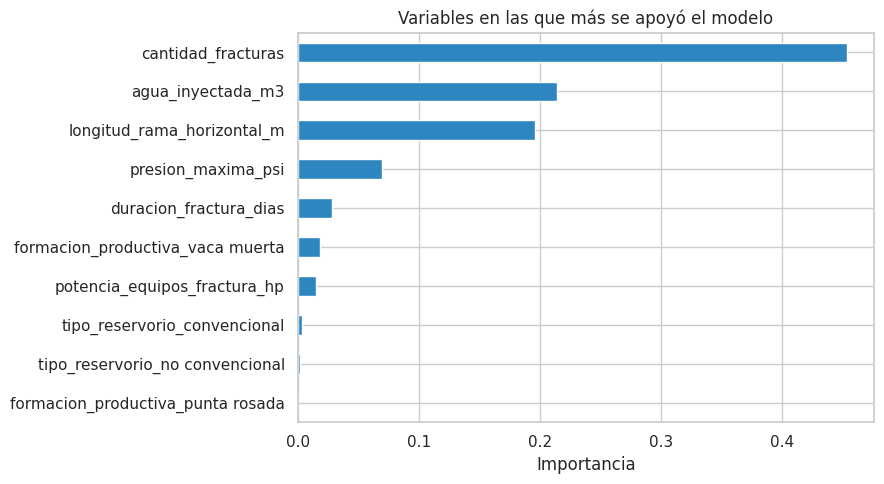

,0
cantidad_fracturas,0.453
agua_inyectada_m3,0.214
longitud_rama_horizontal_m,0.196
presion_maxima_psi,0.070
duracion_fractura_dias,0.028
formacion_productiva_vaca muerta,0.018
potencia_equipos_fractura_hp,0.015
tipo_reservorio_convencional,0.004
tipo_reservorio_no convencional,0.002
formacion_productiva_punta rosada,0.000


In [ ]:
nombres_columnas = modelo_final.named_steps['preprocessor'].get_feature_names_out()
nombres_columnas = [n.replace('num__', '').replace('cat__', '') for n in nombres_columnas]

importancias = pd.Series(
    modelo_final.named_steps['regressor'].feature_importances_,
    index=nombres_columnas,
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
importancias.head(10).sort_values().plot.barh(ax=ax, color='#2E86C1')
ax.set_xlabel('Importancia')
ax.set_title('Variables en las que más se apoyó el modelo')
plt.tight_layout()
plt.show()

importancias.head(10).round(3)

El resultado tiene sentido físico. Las tres variables más importantes, la **cantidad de fracturas**, el **agua inyectada** y la **longitud de la rama horizontal**, describen el tamaño del trabajo: cada etapa de fractura lleva su carga de arena, y una rama horizontal más larga admite más etapas. La arena viaja suspendida en el agua, por eso a más agua, más arena.

La formación y el tipo de reservorio pesan poco por sí solos porque su efecto ya está "contenido" en las variables de tamaño: un pozo de Vaca Muerta se distingue justamente por tener rama horizontal larga y muchas etapas.

## Parte 8. Uso del modelo: predicción para un pozo nuevo

Usamos el mismo pozo hipotético que en la versión anterior del proyecto: un pozo horizontal de Vaca Muerta con 2.200 m de rama y 30 etapas de fractura.

In [ ]:
pozo_futuro = pd.DataFrame([{
    'longitud_rama_horizontal_m': 2200.0,
    'cantidad_fracturas': 30,
    'agua_inyectada_m3': 28000.0,
    'presion_maxima_psi': 13500.0,
    'potencia_equipos_fractura_hp': 25000.0,
    'duracion_fractura_dias': 12,
    'formacion_productiva': 'vaca muerta',
    'tipo_reservorio': 'no convencional',
}])

pred_rf = modelo_final.predict(pozo_futuro)[0]
pred_lr = modelos_finales['Regresión Lineal'].predict(pozo_futuro)[0]

print(f'Arena estimada por el Random Forest optimizado: {pred_rf:,.0f} tn')
print(f'Arena estimada por la Regresión Lineal:         {pred_lr:,.0f} tn')
print(f'Margen típico de error del modelo (MAE en test): ± {m_final["MAE (tn)"]:,.0f} tn')

Arena estimada por el Random Forest optimizado: 6,787 tn
Arena estimada por la Regresión Lineal:         6,757 tn
Margen típico de error del modelo (MAE en test): ± 304 tn


## Parte 9. Conclusiones

- **Tarea:** regresión de la arena total por pozo (`arena_total_tn`) a partir de variables que se conocen al diseñar la fractura. Excluimos las columnas derivadas de la arena para evitar fuga de información.
- **Proceso:** preprocesamiento en `Pipeline` + `ColumnTransformer`, separación 80/20, comparación con validación cruzada contra un `DummyRegressor`, una Regresión Lineal y un Random Forest.
- **Optuna:** 40 pruebas sobre cinco hiperparámetros del Random Forest, minimizando el RMSE de validación cruzada sobre el entrenamiento. El test se usó una sola vez, al final.
- **Resultado:** el Random Forest optimizado es el mejor modelo en test (ver la tabla de la Parte 6). Supera con claridad al piso y reduce el error de la regresión lineal.
- **Utilidad:** con un error típico de unos cientos de toneladas, el modelo sirve para planificar con anticipación la compra y el transporte de arena y dimensionar el stock de seguridad.

**Limitaciones y próximos pasos:**

- El agua inyectada es una de las variables más fuertes, pero también es un dato que se define en el mismo diseño de la fractura. Si en la práctica no se conoce de antemano, convendría reentrenar sin ella y ver cuánto empeora.
- El error crece en los pozos más grandes. Se podría probar transformar la variable objetivo con logaritmo o modelar convencionales y no convencionales por separado.
- Explicabilidad con SHAP para ver el efecto de cada variable pozo por pozo.

- IMPORTANTE A TENER EN CUENTA:
Si bien el modelo de Random Forest funciono mejor en las pruebas, y por eso elegimos continuar con este, también debemos tener en cuenta que si un modelo lineal y uno complejo (como Random Forest) te dan métricas similares, conviene elegir la Regresión Lineal. Esto se debe a:

1. Interpretabilidad
La Regresión Lineal es totalmente transparente. Te da una fórmula matemática exacta con coeficientes claros, mientras que el Random Forest funciona como una "caja negra" compuesta por cientos de árboles votando. Para explicar una predicción necesitas herramientas externas complejas.

2. Simplicidad de Despliegue
La Regresión Lineal es trivial. Una vez que obtienes los coeficientes, la fórmula se puede exportar a un script básico de Python, o incluso replicar en una simple celda de una planilla de Excel o base de datos SQL. Mientras que Random Forest Requiere empaquetar todo el modelo pesado (archivos .pkl o .joblib), librerías específicas en el servidor y más recursos de procesamiento cada vez que quieras hacer una predicción en tiempo real.

3. Velocidad y Costo Computacional
La Regresión Lineal Entrena en milisegundos y consume poquísima memoria. Mientras que el Random Forest es mucho más pesado de entrenar y requiere más recursos de hardware, lo cual no se justifica si al final rinde exactamente igual que la regresión.

Por todo esto es que si deseamos aplicar el modelo en una situación de operación real debería analizar a profundidad si efectivamente vale la pena realizar el random forest, o con el modelo de regresión lineal es suficiente.